# 02 振子与捕食模型

二阶振子和一阶方程组描述同一运动；LV的参考是数值积分，不能称为精确解。

默认仅运行 **smoke**；两轮训练只用于理解流程。把 `MODE` 改成 `reproduction` 才会按文档配置训练。

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Image

# 同时支持从项目根目录或 notebooks 目录启动。
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "请从项目目录打开 Notebook"
sys.path.insert(0, str(ROOT / "src"))
from ndeq_examples.runner import run, environment
MODE = "smoke"
SEED = 42
environment()

<PROJECT_ROOT>\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.12.6',
 'platform': 'Windows-11-10.0.26200-SP0',
 'packages': {'torch': '2.6.0+cpu',
  'neurodiffeq': '0.7.0',
  'numpy': '1.26.4',
  'scipy': '1.15.2',
  'matplotlib': '3.9.2',
  'pandas': '2.2.3',
  'pillow': '10.4.0'},
 'neurodiffeq_module_version': '0.6.3-dev'}

## oscillator

先预测图像的大致形状，再运行下面的共享实现。

oscillator: smoke_passed; numerical_pass=False; <PROJECT_ROOT>\results\notebook_runs\20261012T071938_oscillator_smoke_s42_default_2c678a


{'max_abs': 5.683355512415277,
 'rmse': 3.463419530218445,
 'relative_l2': 4.728094620312138,
 'initial_max_abs': 0.0,
 'condition_max_abs': 0.0,
 'residual_rmse': 3.130331236361619,
 'residual_max_abs': 5.687031362993915,
 'per_component': [{'max_abs': 5.683355512415277,
   'rmse': 3.463419530218445,
   'relative_l2': 4.728094620312138}],
 'reference': {'kind': 'analytic'},
 'test_size': 256,
 'test_seed': 20230403,
 'acceptance': {'relative_l2': 0.02,
  'max_abs': 0.03,
  'residual_rmse': 0.03,
  'condition_max_abs': 1e-08},
 'acceptance_checks': {'relative_l2': False,
  'max_abs': False,
  'residual_rmse': False,
  'condition_max_abs': True},
 'numerical_pass': False,
 'energy_max_drift': 16.133143517534553}

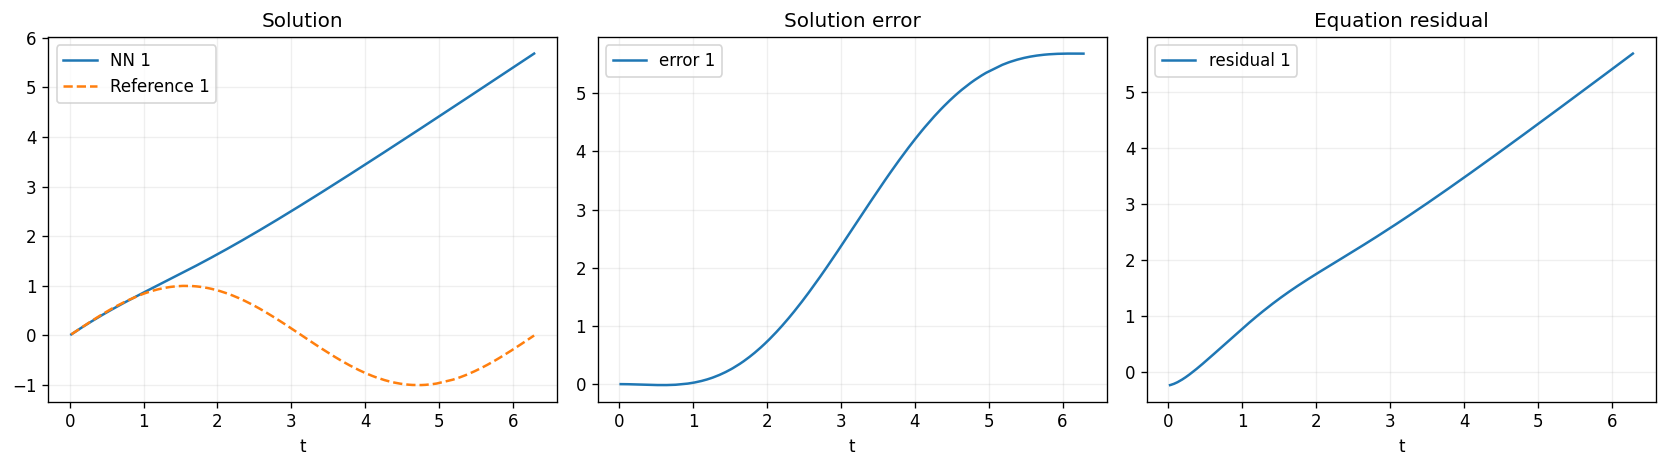

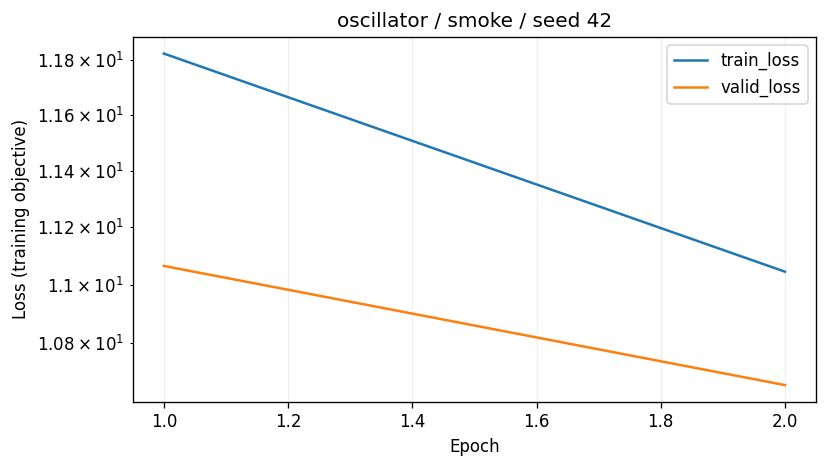

In [2]:
out = run("oscillator", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

## circle

先预测图像的大致形状，再运行下面的共享实现。

circle: smoke_passed; numerical_pass=False; <PROJECT_ROOT>\results\notebook_runs\20261012T071940_circle_smoke_s42_default_4cb2ea


{'max_abs': 1.4693987148402519,
 'rmse': 0.7799336054718465,
 'relative_l2': 1.102992682608832,
 'initial_max_abs': 0.0,
 'condition_max_abs': 0.0,
 'residual_rmse': 0.47654173360938057,
 'residual_max_abs': 1.018084555470877,
 'per_component': [{'max_abs': 1.1265898892340958,
   'rmse': 0.7012524652063421,
   'relative_l2': 0.9573163110313725},
  {'max_abs': 1.4693987148402519,
   'rmse': 0.8513740881249885,
   'relative_l2': 1.2506477675149275}],
 'reference': {'kind': 'analytic'},
 'test_size': 256,
 'test_seed': 20230403,
 'acceptance': {'relative_l2': 0.02,
  'max_abs': 0.03,
  'residual_rmse': 0.03,
  'condition_max_abs': 1e-08},
 'acceptance_checks': {'relative_l2': False,
  'max_abs': False,
  'residual_rmse': False,
  'condition_max_abs': True},
 'numerical_pass': False,
 'energy_max_drift': 0.37513381684477054}

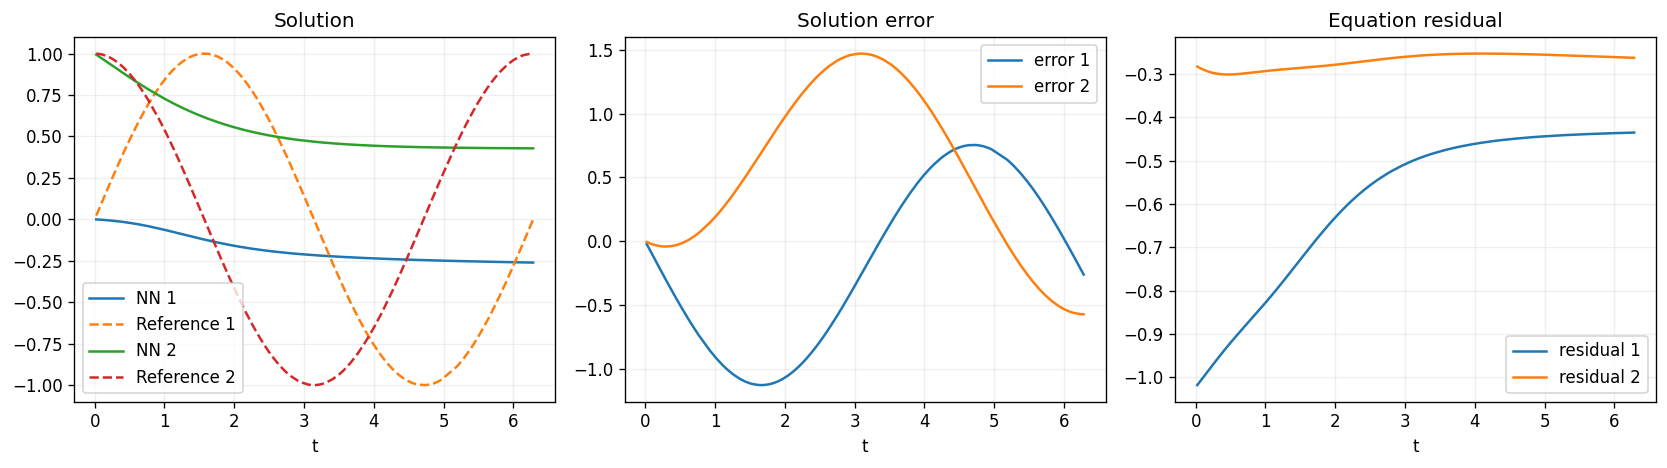

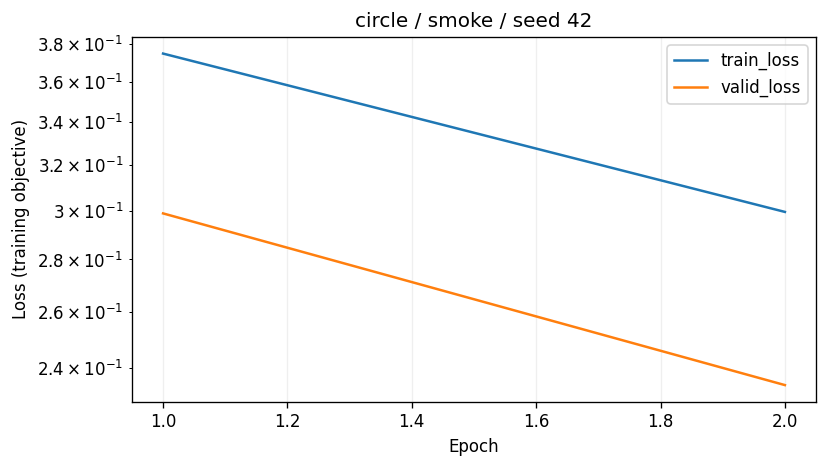

In [3]:
out = run("circle", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

## lotka

先预测图像的大致形状，再运行下面的共享实现。

lotka: smoke_passed; numerical_pass=False; <PROJECT_ROOT>\results\notebook_runs\20261012T071941_lotka_smoke_s42_default_1ec85c


{'max_abs': 0.688774996508306,
 'rmse': 0.3144605565769279,
 'relative_l2': 0.3023878308319126,
 'initial_max_abs': 0.0,
 'condition_max_abs': 0.0,
 'residual_rmse': 0.2548047957578781,
 'residual_max_abs': 0.6872821815698705,
 'per_component': [{'max_abs': 0.44171278156550986,
   'rmse': 0.30597289240381137,
   'relative_l2': 0.3068542941979695},
  {'max_abs': 0.688774996508306,
   'rmse': 0.3227250724678642,
   'relative_l2': 0.2985351597394357}],
 'reference': {'kind': 'numerical DOP853',
  'rtol': 1e-11,
  'atol': 1e-13,
  'check_rtol': 1e-09,
  'check_atol': 1e-11,
  'convergence_max_abs': 2.0166470715565765e-09},
 'test_size': 256,
 'test_seed': 20230403,
 'acceptance': {'relative_l2': 0.02,
  'max_abs': 0.03,
  'residual_rmse': 0.03,
  'condition_max_abs': 1e-08},
 'acceptance_checks': {'relative_l2': False,
  'max_abs': False,
  'residual_rmse': False,
  'condition_max_abs': True},
 'numerical_pass': False}

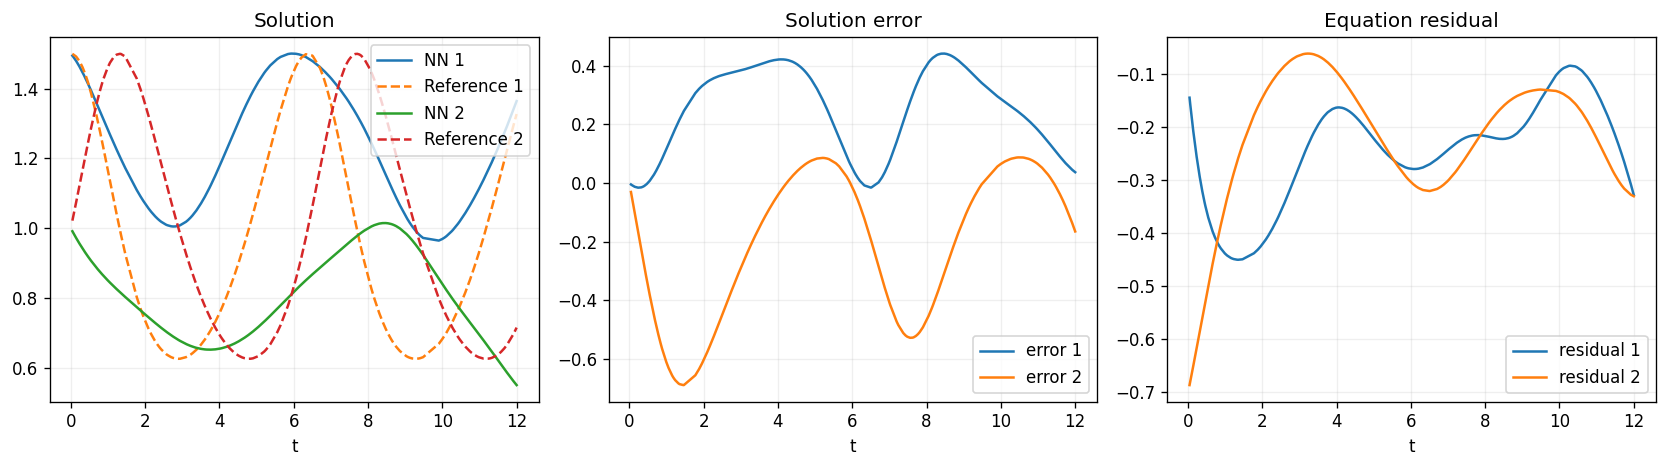

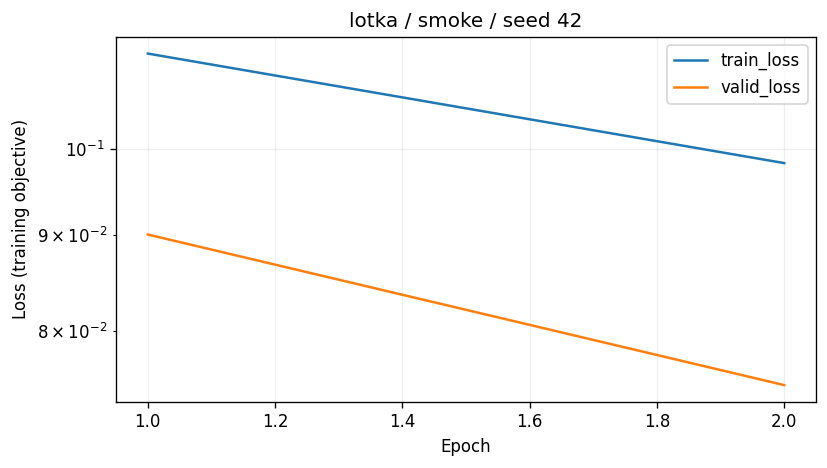

In [4]:
out = run("lotka", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

## 自查

- 这里的未知函数和自变量分别是什么？
- 初始/边界条件如何施加？
- metrics里哪一项是方程残差，哪一项是解误差？
- 当前是流程验证，还是完整训练？

详细说明见 `docs/learning_guide_zh.md` 和 `docs/validation_protocol.md`。